In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage


In [2]:
# Load Iris dataset

iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("First 5 Records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)


First 5 Records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape:
(150, 4)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='str')


In [3]:
# Select numerical features for clustering
X = df.copy()

print("Selected Features:")
print(X.head())

Selected Features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [4]:
# Create StandardScaler object
scaler = StandardScaler()

# Standardize the dataset
X_scaled = scaler.fit_transform(X)

print("Standardized Data:")
print(X_scaled[:5])


Standardized Data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


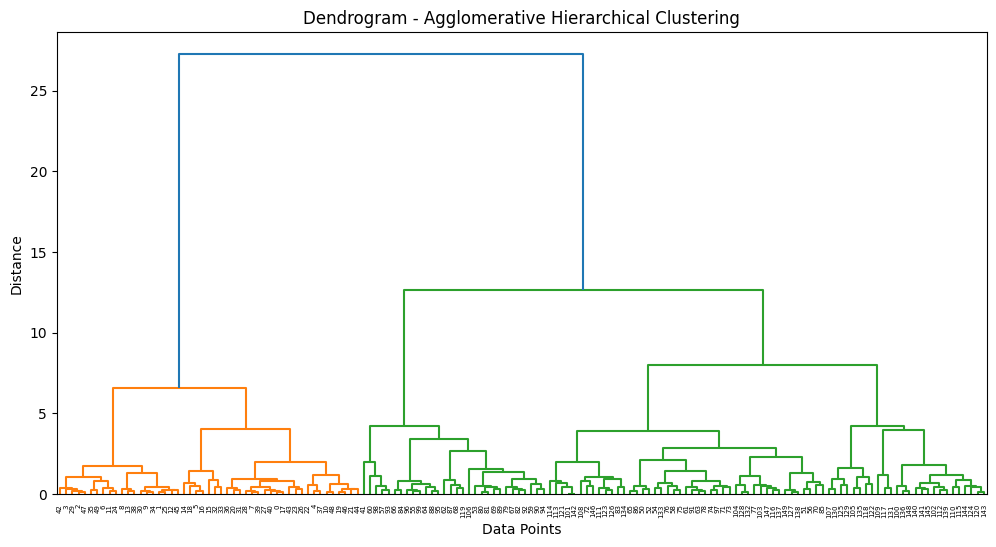

In [5]:
# Perform hierarchical clustering
Z = linkage(X_scaled, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(Z)

plt.title("Dendrogram - Agglomerative Hierarchical Clustering")
plt.xlabel("Data Points")
plt.ylabel("Distance")

plt.show()


In [6]:
# Set number of clusters
n_clusters = 3

# Create Agglomerative Clustering model
model = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage='ward'
)

# Fit the model and predict clusters
labels = model.fit_predict(X_scaled)

# Add cluster labels to dataset
df['cluster'] = labels

print("Clustering Completed!")

print("\nFirst 10 Records:")
display(df.head(10))

print("\nCluster Counts:")
print(df['cluster'].value_counts().sort_index())


Clustering Completed!

First 10 Records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1
5,5.4,3.9,1.7,0.4,1
6,4.6,3.4,1.4,0.3,1
7,5.0,3.4,1.5,0.2,1
8,4.4,2.9,1.4,0.2,1
9,4.9,3.1,1.5,0.1,1



Cluster Counts:
cluster
0    71
1    49
2    30
Name: count, dtype: int64


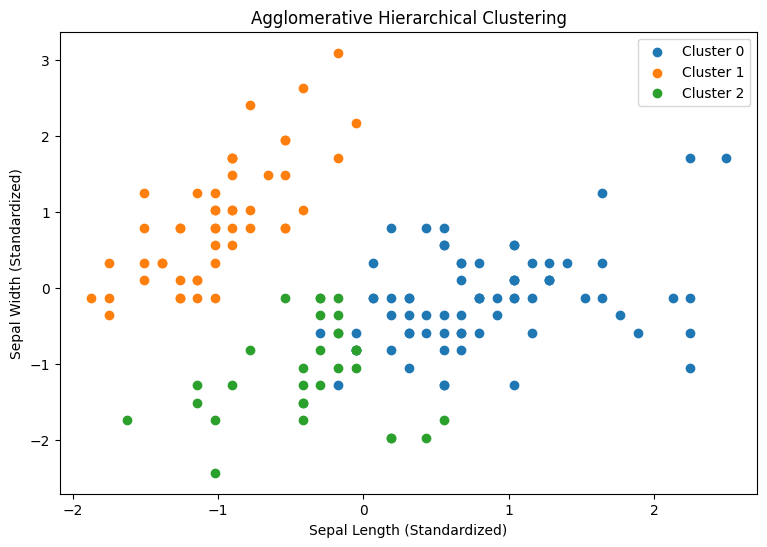

In [7]:
plt.figure(figsize=(9, 6))

for cluster_id in sorted(df['cluster'].unique()):

    # Select records belonging to a cluster
    mask = df['cluster'] == cluster_id

    # Plot the cluster
    plt.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f'Cluster {cluster_id}'
    )

plt.title("Agglomerative Hierarchical Clustering")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")

plt.legend()
plt.show()


In [8]:
# Calculate mean values for each cluster
cluster_summary = df.groupby('cluster').mean()

print("Cluster Summary:")
display(cluster_summary)


Cluster Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
cluster,,,,
0,6.546479,2.992958,5.267606,1.854930
1,5.016327,3.451020,1.465306,0.244898
2,5.530000,2.566667,3.930000,1.206667
